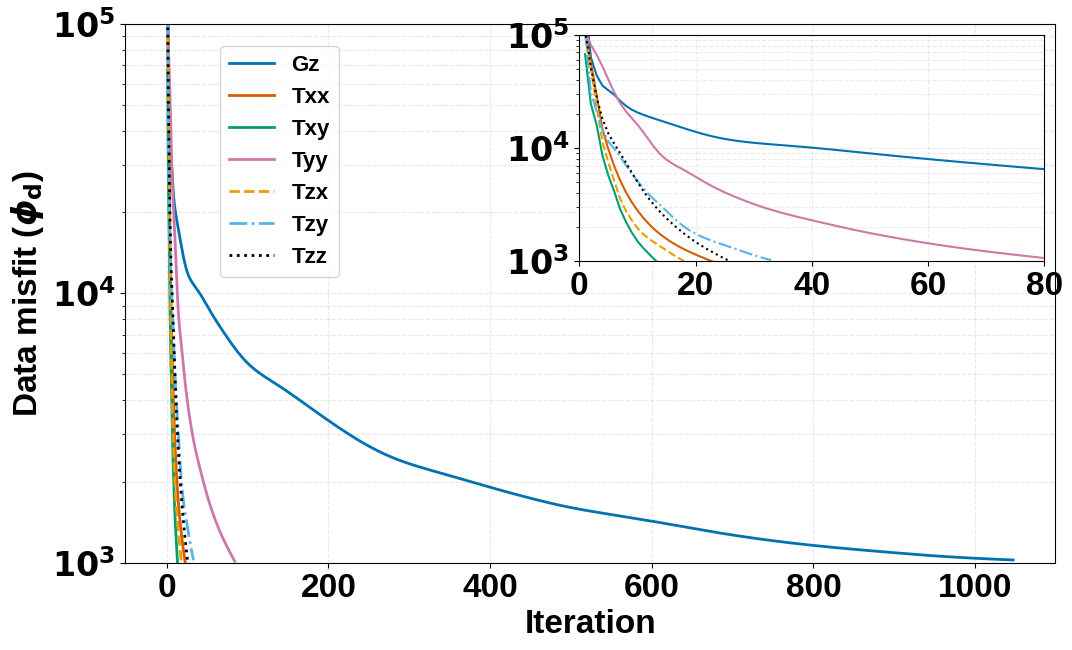

Saved: All_Convergence_Curves_7_Components.png


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib as mpl
from PIL import Image, ImageChops

# =====================================================================
# GLOBAL PUBLICATION SETTINGS
# =====================================================================
BG=AX="white"; TC="black"; DPI=600
mpl.rcParams.update({
    "font.family":"Liberation Sans","font.size":24,
    "axes.labelsize":24,"axes.titlesize":24,"xtick.labelsize":24,"ytick.labelsize":24,
    "legend.fontsize":16,"figure.facecolor":"white",
    "axes.facecolor":"white","savefig.dpi":600,
    "savefig.facecolor":"white","axes.edgecolor":"black",
    "axes.linewidth":.8,"xtick.color":"black","ytick.color":"black",
    "text.color":"black","axes.labelcolor":"black",
    "ps.fonttype":42,"font.weight":"bold","axes.labelweight":"bold",
    "axes.titleweight":"bold"
})

def save_fig(fig,filename,tight=True):
    # fig.tight_layout()
    kw={"dpi":600,"facecolor":BG,"pad_inches":0.8}
    if tight:kw["bbox_inches"]="tight"
    fig.savefig(filename,**kw)
    plt.show()
    plt.close(fig)
    crop_white_margin(filename,padding=0)
    print("Saved:",filename)

def crop_white_margin(filename,padding=0):
    img=Image.open(filename).convert("RGB")
    bbox=ImageChops.difference(img,Image.new("RGB",img.size,"white")).getbbox()
    if bbox:
        x0,y0,x1,y1=bbox
        img.crop((max(0,x0-padding),max(0,y0-padding),
                  min(img.width,x1+padding),min(img.height,y1+padding))
                ).save(filename,dpi=(DPI,DPI))
# ==============================================================
# CONVERGENCE DATA, COLOURS AND LINE STYLES
# ==============================================================
files={
    "Gz":"two_P_gz_Conver_Data.xlsx","Txx":"two_P_txx_Conver_Data.xlsx",
    "Txy":"two_P_txy_Conver_Data.xlsx","Tyy":"two_P_tyy_Conver_Data.xlsx",
    "Tzx":"two_P_tzx_Conver_Data.xlsx","Tzy":"two_P_tzy_Conver_Data.xlsx",
    "Tzz":"two_P_tzz_Conver_Data.xlsx"
}
colors={
    "Gz":"#0072B2","Txx":"#D55E00","Txy":"#009E73","Tyy":"#CC79A7",
    "Tzx":"#E69F00","Tzy":"#56B4E9","Tzz":"#000000"
}
styles={
    "Gz":"-","Txx":"-","Txy":"-","Tyy":"-",
    "Tzx":"--","Tzy":"-.","Tzz":":"
}
# ==============================================================
# MAIN CONVERGENCE PLOT
# ==============================================================
fig,ax=plt.subplots(figsize=(12,7)); data={}

for label,file in files.items():
    df=pd.read_excel(file); data[label]=df
    ax.semilogy(df["Iteration"],df["phi_d"],lw=2,
                color=colors[label],linestyle=styles[label],label=label)

ax.set_xlabel("Iteration")
ax.set_ylabel(r"Data misfit ($\phi_{\mathbf{d}}$)")
ax.tick_params(direction="out")
ax.grid(True,which="both",linestyle="--",alpha=.3)

# Y-axis: 10³–10⁵
yticks=[10**3,10**4,10**5]
ax.set_ylim(10**3,10**5); ax.set_yticks(yticks)
ax.set_yticklabels([r"$\mathbf{10^3}$",
    r"$\mathbf{10^4}$",
    r"$\mathbf{10^5}$"])

# Main legend
ax.legend(loc="upper left",bbox_to_anchor=(.09,.98),
          frameon=True)

# ==============================================================
# ZOOMED INSET: FIRST 50 ITERATIONS
# ==============================================================
axins=inset_axes(ax,width="50%",height="42%",loc="upper right")

for label,df in data.items():
    d=df[df["Iteration"]<=80]
    axins.semilogy(d["Iteration"],d["phi_d"],lw=1.5,
                   color=colors[label],linestyle=styles[label])

axins.set_xlim(0,80); axins.set_ylim(10**3,10**5)
axins.set_yticks(yticks)
axins.set_yticklabels([r"$\mathbf{10^3}$",
    r"$\mathbf{10^4}$",
    r"$\mathbf{10^5}$"])
axins.grid(True,which="both",linestyle="--",alpha=.25)
axins.tick_params(direction="out")

# ==============================================================
# LAYOUT AND SAVE
# ==============================================================
save_fig(fig,"All_Convergence_Curves_7_Components.png")